# GLM analysis

**Scope:** Inspect task onset CSV; construct design matrix; regressor correlations; fit GLM; contrasts; atlas interpretation.

> Template only — choose and document Neurodesk tools, inspect input data, and validate outputs before implementation.


## 0. Setup and input data

In [1]:
# General imports
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

from nilearn import image, plotting
from nilearn.masking import compute_epi_mask
from nilearn.glm.first_level import FirstLevelModel
from nilearn.glm import threshold_stats_img

# Project paths
PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
FUNC_DATA_DIR = DATA_DIR / "fMRI" / "tfMRI_LANGUAGE_LR"
FUNC_PREPROC_DIR = PROJECT_ROOT / "outputs" / "functional"
GLM_DIR = PROJECT_ROOT / "outputs" / "glm"
FIRST_LEVEL_DIR = GLM_DIR / "first_level"

FIRST_LEVEL_DIR.mkdir(parents=True, exist_ok=True)

FMRI_CANDIDATES = [
    FUNC_PREPROC_DIR / "tfMRI_LANGUAGE_LR_mcf_smooth.nii.gz",
    FUNC_PREPROC_DIR / "tfMRI_LANGUAGE_LR_mcf.nii.gz",
    FUNC_DATA_DIR / "tfMRI_LANGUAGE_LR.nii.gz",
]

DESIGN_MATRIX_PATH = GLM_DIR / "design_matrix.csv"
EVENTS_PATH = GLM_DIR / "glm_events.csv"
MNI_2MM_PATH = Path(os.environ.get("FSLDIR", "")) / "data" / "standard" / "MNI152_T1_2mm_brain.nii.gz"

fmri_path = next((p for p in FMRI_CANDIDATES if p.is_file()), None)
if fmri_path is None:
    raise FileNotFoundError(
        "No functional image found. Checked:\n" +
        "\n".join(str(p) for p in FMRI_CANDIDATES) +
        "\nUpdate FMRI_CANDIDATES to point to the final preprocessed 4D image."
    )

if not DESIGN_MATRIX_PATH.is_file():
    raise FileNotFoundError(
        f"Design matrix not found: {DESIGN_MATRIX_PATH}. Run glm_design first."
    )

print("Project root:", PROJECT_ROOT)
print("Functional image:", fmri_path)
print("Design matrix:", DESIGN_MATRIX_PATH)
print("Output directory:", FIRST_LEVEL_DIR)

Project root: /data/Desktop/myfiles/NX421-MiniProject-1
Functional image: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/functional/tfMRI_LANGUAGE_LR_mcf_smooth.nii.gz
Design matrix: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/glm/design_matrix.csv
Output directory: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/glm/first_level


## 1) First-level GLM (3c)

The model uses the explicit design matrix from tasks 3a and 3b, so the event timing, SPM HRF convolution, high-pass cosine terms, motion regressors, and spike regressors are carried into the GLM. The image is already smoothed by the preceding preprocessing workflow, so no additional smoothing is applied here.

### 1.1) fMRI data and design matrix loading

checks compatibility between the two, and reports basic diagnostics before fitting the GLM.

In [2]:
# Load the 4D functional image and design matrix
fmri_img = nib.load(str(fmri_path))
if len(fmri_img.shape) != 4:
    raise ValueError(f"Expected a 4D fMRI image, got shape {fmri_img.shape}")

n_scans = fmri_img.shape[3]
zooms = fmri_img.header.get_zooms()
t_r = float(zooms[3])

design_matrix = pd.read_csv(DESIGN_MATRIX_PATH, index_col=0)

# Drop a stray saved index column if the CSV was written differently.
design_matrix = design_matrix.loc[:, ~design_matrix.columns.astype(str).str.match(r"^Unnamed:")]

required_task_columns = ["story", "math", "cue"]
missing_columns = [c for c in required_task_columns if c not in design_matrix.columns]
if missing_columns:
    raise ValueError(
        f"Missing task columns {missing_columns}. Available columns: {list(design_matrix.columns)}"
    )

if len(design_matrix) != n_scans:
    raise ValueError(
        f"Design matrix has {len(design_matrix)} rows but the fMRI has {n_scans} volumes. "
        "Rerun glm_design using the same final functional image selected here."
    )

if not np.isfinite(design_matrix.to_numpy(dtype=float)).all():
    raise ValueError("The design matrix contains NaN or infinite values.")

print("Functional image shape:", fmri_img.shape)
print("Voxel sizes (mm; TR in seconds):", zooms)
print(f"TR: {t_r:.4f} s")
print("Design matrix shape:", design_matrix.shape)
print("Design matrix rank:", np.linalg.matrix_rank(design_matrix.to_numpy(dtype=float)))
print("Number of regressors:", len(design_matrix.columns))

rank = np.linalg.matrix_rank(design_matrix.to_numpy(dtype=float))
if rank < design_matrix.shape[1]:
    warnings.warn(
        "The design matrix is rank deficient. Some regressors are linearly dependent; "
        "inspect the design-matrix/correlation diagnostics."
    )

Functional image shape: (91, 109, 91, 316)
Voxel sizes (mm; TR in seconds): (np.float32(2.0), np.float32(2.0), np.float32(2.0), np.float32(0.72))
TR: 0.7200 s
Design matrix shape: (316, 21)
Design matrix rank: 21
Number of regressors: 21


### 1.2) EPI Mask creation

The mask restricts GLM estimation to selected brain voxels rather than analyzing the entire image, including background.

EPI mask: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/glm/first_level/epi_mask.nii.gz
Voxels in mask: 207772


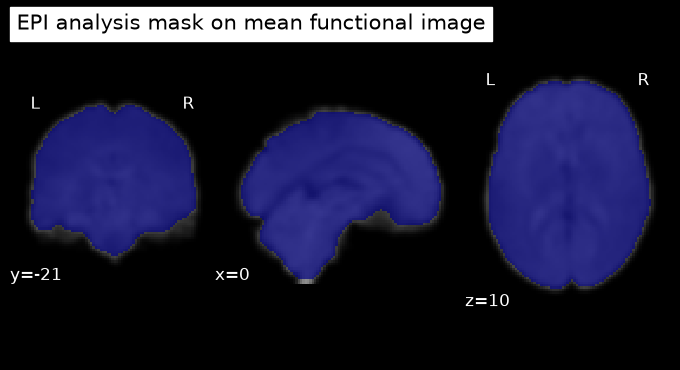

In [3]:
# Keeps model estimation in functional-image space.
mask_img = compute_epi_mask(fmri_img)
mask_path = FIRST_LEVEL_DIR / "epi_mask.nii.gz"
mask_img.to_filename(str(mask_path))

mask_voxels = int(np.asarray(mask_img.dataobj).sum())
if mask_voxels == 0:
    raise RuntimeError("The computed EPI mask is empty. Inspect the functional image and mask.")

print("EPI mask:", mask_path)
print("Voxels in mask:", mask_voxels)

# Visual: mean functional image and EPI mask
mean_func = image.mean_img(fmri_img)
display = plotting.plot_roi(
    mask_img,
    bg_img=mean_func,
    title="EPI analysis mask on mean functional image",
    display_mode="ortho",
    draw_cross=False
)
plotting.show()

### 1.3) Model initialization and first-level GLM fiting

In [4]:
# Uses the the supplied design matrix, already containing task, motion, spike, and drift regressors. 
first_level_model = FirstLevelModel(
    t_r=t_r,
    mask_img=mask_img,
    noise_model="ar1",
    standardize=False,
    signal_scaling=False,
    smoothing_fwhm=None,
    minimize_memory=False,
    verbose=1,
)

first_level_model = first_level_model.fit(
    run_imgs=fmri_img,
    design_matrices=design_matrix,
)

print("First-level GLM fit completed.")

Computing run 1 out of 1 runs (go take a coffee, a big one)


First-level GLM fit completed.



Computation of 1 runs done in 9.570432424545288 seconds.



### 1.4) Task-regressor statistical maps

For each task regressor, the contrast tests its coefficient against zero while accounting for the other regressors in the design matrix. Maps are saved unthresholded first so that effect estimates and statistics remain available regardless of display threshold.

Calculates five output maps for each condition using compute_contrast():
- effect_size: estimated effect (beta contrast).
- effect_variance: estimated variance of that effect.
- stat: statistical test statistic for the contrast.
- z_score: the statistic expressed as a Z-score.
- p_value: the associated p-value map.

In [5]:
# Save effect estimates and statistical maps for each task regressor.
task_map_paths = {}
task_contrasts = {}

for condition in required_task_columns:
    contrast_vector = np.zeros(len(design_matrix.columns), dtype=float)
    contrast_vector[design_matrix.columns.get_loc(condition)] = 1.0
    task_contrasts[condition] = contrast_vector

    condition_dir = FIRST_LEVEL_DIR / condition
    condition_dir.mkdir(parents=True, exist_ok=True)

    outputs = {
        "effect_size": first_level_model.compute_contrast(contrast_vector, output_type="effect_size"),
        "effect_variance": first_level_model.compute_contrast(contrast_vector, output_type="effect_variance"),
        "stat": first_level_model.compute_contrast(contrast_vector, output_type="stat"),
        "z_score": first_level_model.compute_contrast(contrast_vector, output_type="z_score"),
        "p_value": first_level_model.compute_contrast(contrast_vector, output_type="p_value"),
    }

    task_map_paths[condition] = {}
    for output_type, stat_img in outputs.items():
        out_path = condition_dir / f"{condition}_{output_type}.nii.gz"
        stat_img.to_filename(str(out_path))
        task_map_paths[condition][output_type] = out_path

    print(f"{condition}:")
    for output_type, out_path in task_map_paths[condition].items():
        print(f"  {output_type}: {out_path.relative_to(PROJECT_ROOT)}")

# Saves task contrast vectors as a table.
task_vector_df = pd.DataFrame(task_contrasts, index=design_matrix.columns)
task_vector_df.to_csv(FIRST_LEVEL_DIR / "task_contrast_vectors.csv")
task_vector_df

story:
  effect_size: outputs/glm/first_level/story/story_effect_size.nii.gz
  effect_variance: outputs/glm/first_level/story/story_effect_variance.nii.gz
  stat: outputs/glm/first_level/story/story_stat.nii.gz
  z_score: outputs/glm/first_level/story/story_z_score.nii.gz
  p_value: outputs/glm/first_level/story/story_p_value.nii.gz
math:
  effect_size: outputs/glm/first_level/math/math_effect_size.nii.gz
  effect_variance: outputs/glm/first_level/math/math_effect_variance.nii.gz
  stat: outputs/glm/first_level/math/math_stat.nii.gz
  z_score: outputs/glm/first_level/math/math_z_score.nii.gz
  p_value: outputs/glm/first_level/math/math_p_value.nii.gz
cue:
  effect_size: outputs/glm/first_level/cue/cue_effect_size.nii.gz
  effect_variance: outputs/glm/first_level/cue/cue_effect_variance.nii.gz
  stat: outputs/glm/first_level/cue/cue_stat.nii.gz
  z_score: outputs/glm/first_level/cue/cue_z_score.nii.gz
  p_value: outputs/glm/first_level/cue/cue_p_value.nii.gz


,story,math,cue
cue,0.0,0.0,1.0
math,0.0,1.0,0.0
story,1.0,0.0,0.0
rot_x,0.0,0.0,0.0
rot_y,0.0,0.0,0.0
rot_z,0.0,0.0,0.0
trans_x,0.0,0.0,0.0
trans_y,0.0,0.0,0.0
trans_z,0.0,0.0,0.0
rot_x_deriv,0.0,0.0,0.0


### 1.4.1) Statistical maps display

Visualize the unthresholded z-statistic maps with an exploratory |Z| display threshold.

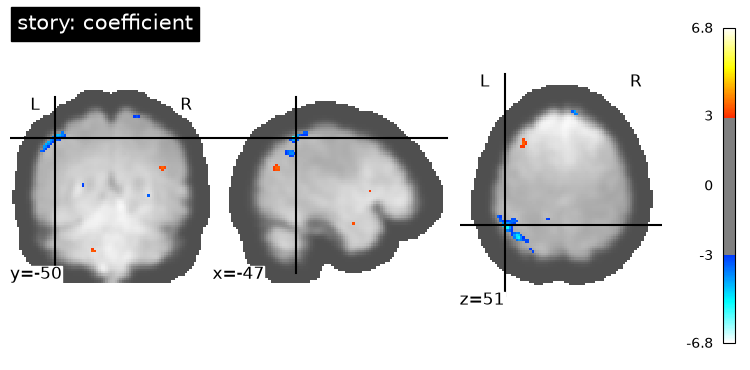

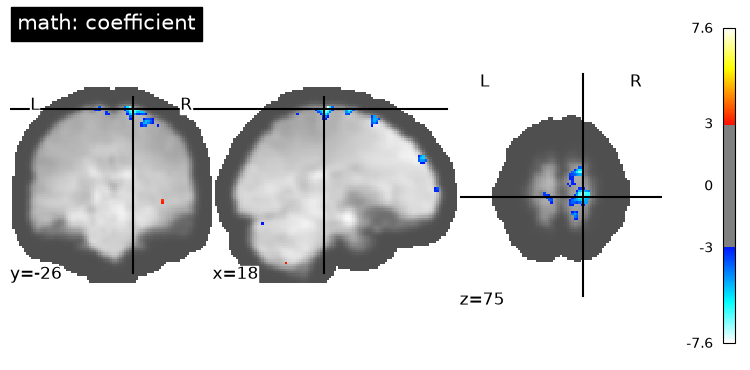

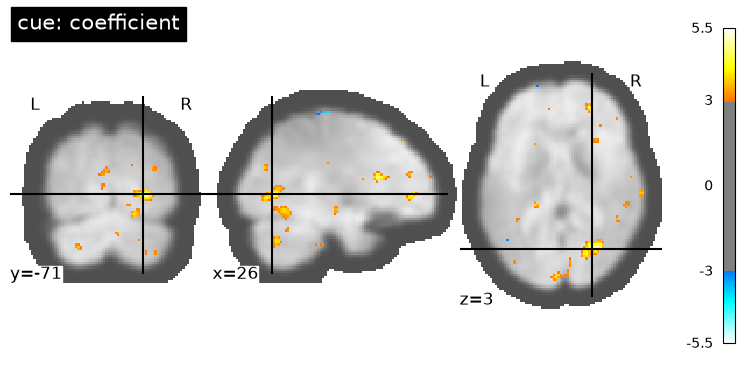

In [6]:
# The mean functional image is used as background to avoid assuming MNI registration.
for condition in required_task_columns:
    z_map = task_map_paths[condition]["z_score"]
    display = plotting.plot_stat_map(
        z_map,
        bg_img=mean_func,
        title=f"{condition}: coefficient",
        threshold=3.0,
        display_mode="ortho",
        black_bg=False,
        colorbar=True,
    )
    plotting.show()

### 1.4.2) Voxel-wise False Discovery Rate correction (optional)

Helps to identify voxels with statistically significant effects. If no voxels survive correction, the unthresholded maps remain saved.

In [7]:
fdr_results = []

for condition in required_task_columns:
    z_map = task_map_paths[condition]["z_score"]
    try:
        thresholded_map, threshold = threshold_stats_img(
            z_map,
            alpha=0.05,
            height_control="fdr",
            cluster_threshold=0,
            two_sided=True,
        )
        out_path = FIRST_LEVEL_DIR / condition / f"{condition}_z_FDR05.nii.gz"
        thresholded_map.to_filename(str(out_path))
        fdr_results.append({
            "contrast": f"{condition} > implicit baseline",
            "FDR_alpha": 0.05,
            "z_threshold": float(threshold),
            "saved_map": str(out_path.relative_to(PROJECT_ROOT)),
        })
        print(f"{condition}: FDR threshold = {threshold:.3f}; saved {out_path.name}")
    except Exception as exc:
        fdr_results.append({
            "contrast": f"{condition} > implicit baseline",
            "FDR_alpha": 0.05,
            "z_threshold": np.nan,
            "saved_map": "No FDR map generated",
        })
        print(f"{condition}: FDR thresholding could not be completed: {exc}")

fdr_summary = pd.DataFrame(fdr_results)
fdr_summary.to_csv(FIRST_LEVEL_DIR / "fdr_threshold_summary.csv", index=False)
fdr_summary

story: FDR threshold = 4.029; saved story_z_FDR05.nii.gz
math: FDR threshold = 3.854; saved math_z_FDR05.nii.gz
cue: FDR threshold = 4.103; saved cue_z_FDR05.nii.gz


,contrast,FDR_alpha,z_threshold,saved_map
0,story > implicit baseline,0.05,4.028858,outputs/glm/first_level/story/story_z_FDR05.ni...
1,math > implicit baseline,0.05,3.854019,outputs/glm/first_level/math/math_z_FDR05.nii.gz
2,cue > implicit baseline,0.05,4.102946,outputs/glm/first_level/cue/cue_z_FDR05.nii.gz


## 2) Story versus Math contrast

The contrast vector assigns `+1` to the `story` column, `−1` to the `math` column, and `0` to all other columns. Positive values indicate greater fitted response during story than math; negative values indicate greater fitted response during math than story. The vector length and column order must match the fitted design matrix.

In [8]:
story_math_vector = np.zeros(len(design_matrix.columns), dtype=float)
story_math_vector[design_matrix.columns.get_loc("story")] = 1.0
story_math_vector[design_matrix.columns.get_loc("math")] = -1.0

contrast_vector_table = pd.DataFrame({
    "regressor": design_matrix.columns,
    "weight_story_minus_math": story_math_vector,
})
contrast_vector_table.to_csv(FIRST_LEVEL_DIR / "story_minus_math_contrast_vector.csv", index=False)

print("Story − Math contrast vector:")
display(contrast_vector_table[contrast_vector_table["weight_story_minus_math"] != 0])
print("Full vector (design-matrix column order):")
print(story_math_vector.tolist())

Story − Math contrast vector:


TypeError: 'OrthoSlicer' object is not callable

In [ ]:
story_math_dir = FIRST_LEVEL_DIR / "story_minus_math"
story_math_dir.mkdir(parents=True, exist_ok=True)

story_math_outputs = {
    "effect_size": first_level_model.compute_contrast(story_math_vector, output_type="effect_size"),
    "effect_variance": first_level_model.compute_contrast(story_math_vector, output_type="effect_variance"),
    "stat": first_level_model.compute_contrast(story_math_vector, output_type="stat"),
    "z_score": first_level_model.compute_contrast(story_math_vector, output_type="z_score"),
    "p_value": first_level_model.compute_contrast(story_math_vector, output_type="p_value"),
}

story_math_paths = {}
for output_type, stat_img in story_math_outputs.items():
    out_path = story_math_dir / f"story_minus_math_{output_type}.nii.gz"
    stat_img.to_filename(str(out_path))
    story_math_paths[output_type] = out_path
    print(f"{output_type}: {out_path.relative_to(PROJECT_ROOT)}")

# Reverse contrast
math_story_vector = -story_math_vector
math_story_z = first_level_model.compute_contrast(math_story_vector, output_type="z_score")
math_story_z_path = story_math_dir / "math_minus_story_z_score.nii.gz"
math_story_z.to_filename(str(math_story_z_path))
print("Reverse contrast z map:", math_story_z_path.relative_to(PROJECT_ROOT))

### 2.1) Activation map plotting

Threshold is set at 3.0

In [ ]:
display = plotting.plot_stat_map(
    story_math_paths["z_score"],
    bg_img=mean_func,
    title="Story − Math (z map; positive = Story > Math)",
    threshold=3.0,
    display_mode="ortho",
    black_bg=False,
    colorbar=True,
)
plotting.show()

display = plotting.plot_stat_map(
    story_math_paths["effect_size"],
    bg_img=mean_func,
    title="Story − Math effect estimate (beta contrast)",
    threshold=None,
    display_mode="ortho",
    black_bg=False,
    colorbar=True,
)
plotting.show()

### 2.2) Voxel-wise False Discovery Rate correction (optional)

Same principle as in 1.4.2)

In [ ]:
try:
    story_math_fdr, story_math_fdr_threshold = threshold_stats_img(
        story_math_paths["z_score"],
        alpha=0.05,
        height_control="fdr",
        cluster_threshold=0,
        two_sided=True,
    )
    story_math_fdr_path = story_math_dir / "story_minus_math_z_FDR05.nii.gz"
    story_math_fdr.to_filename(str(story_math_fdr_path))
    print(f"FDR z threshold: {story_math_fdr_threshold:.3f}")
    print("Saved:", story_math_fdr_path.relative_to(PROJECT_ROOT))

    plotting.plot_stat_map(
        story_math_fdr,
        bg_img=mean_func,
        title="Story − Math (voxelwise FDR q < .05)",
        threshold=0,
        display_mode="ortho",
        black_bg=False,
        colorbar=True,
    )
    plotting.show()
except Exception as exc:
    print("FDR thresholding did not produce a map:", exc)
    print("Use the saved unthresholded z map and report that no corrected map was available.")

## 3) Numerical versus semantic processing discussion


### Contrast interpretation
- **Story > Math**: voxels where the fitted response is greater during story than math.
- **Story < Math**: voxels where the fitted response is greater during math than story.
- **Story, Math, or Cue**: each task coefficient relative to the model's implicit baseline, not a direct comparison of two tasks.

### Networks and candidate systems

after results

## 4) — Literature-based semantic-language processing

### Regions that should stand out
- **Left inferior frontal gyrus:** often associated with controlled semantic retrieval, selection, and aspects of language processing.
- **Middle and posterior temporal cortex:** important for mapping linguistic input to lexical and semantic representations.
- **Anterior temporal cortex:** often implicated in integrating conceptual knowledge across modalities.
- **Angular gyrus:** may contribute to narrative integration, event/situation models, and internally directed semantic processing.

### Possible reasons that can explain some regions absences
1. **Contrast and baseline choice:** Story − Math isolates differences between two active conditions. A region engaged by both conditions may cancel out, even if it is active during both tasks relative to baseline. Conversely, story-versus-baseline effects can include sensory, attention, and general task effects.
2. **Single-subject statistical power and noise:** one run from one participant has limited observations; physiological noise, residual motion, susceptibility distortion, and low signal-to-noise ratio can reduce sensitivity. Multiple-comparison correction also makes detection more conservative.
3. **Model specification and event timing:** incorrect onset units, duration errors, removed-volume offsets, or a mismatch between the final fMRI run and the design matrix can attenuate or misplace task effects. The SPM HRF is an approximation to each participant's response.
4. **Preprocessing and spatial alignment:** smoothing blurs small or adjacent regions; imperfect normalization can make literature-based coordinates misleading; temporal filtering or aggressive censoring can remove useful variance. The structural T1w transform does not automatically put the functional data in MNI space.
5. **Individual variability and network boundaries:** language lateralization and functional topography vary across people. Networks highlighted by litterature are broad reference maps and do not precisely predict an individual task-activation pattern.


## Inventory and summary

In [ ]:
output_files = sorted(p for p in FIRST_LEVEL_DIR.rglob("*") if p.is_file())
inventory = pd.DataFrame({
    "relative_path": [str(p.relative_to(PROJECT_ROOT)) for p in output_files],
    "size_MB": [round(p.stat().st_size / (1024 ** 2), 3) for p in output_files],
})
inventory.to_csv(FIRST_LEVEL_DIR / "output_inventory.csv", index=False)

model_summary = pd.DataFrame([{
    "functional_image": str(fmri_path.relative_to(PROJECT_ROOT)),
    "n_scans": n_scans,
    "TR_seconds": t_r,
    "design_matrix_rows": len(design_matrix),
    "design_matrix_columns": len(design_matrix.columns),
    "design_matrix_rank": int(np.linalg.matrix_rank(design_matrix.to_numpy(dtype=float))),
    "mask_voxels": mask_voxels,
    "contrast_of_interest": "story - math",
    "output_directory": str(FIRST_LEVEL_DIR.relative_to(PROJECT_ROOT)),
}])
model_summary.to_csv(FIRST_LEVEL_DIR / "model_summary.csv", index=False)

print("First-level GLM outputs")
print("-" * 70)
print(model_summary.to_string(index=False))
print(f"\nNumber of output files: {len(output_files)}")
print("Inventory:", FIRST_LEVEL_DIR / "output_inventory.csv")
display(inventory)

## References

1. Binder, J. R., Gross, W. L., Allendorfer, J. B., Bonilha, L., Chapin, J., Edwards, J.
C., ... & Weaver, K. E. (2011). Mapping anterior temporal lobe language areas with
fMRI: a multicenter normative study. Neuroimage, 54(2), 1465-1475.
2. Yeo, BT Thomas, Fenna M. Krienen, Jorge Sepulcre, Mert R. Sabuncu, Danial
Lashkari, Marisa Hollinshead, Joshua L. Roffman et al. "The organization of the
human cerebral cortex estimated by intrinsic functional connectivity." Journal of
neurophysiology (2011).
